# Step 3 — Pre-filtering the photograph pool

Run this notebook from the `02_prefilter` folder. Set `SRC` below to the food photographs folder. Scripts and dependencies are in `scripts/`; generated photos, tables and diagnostic sheets are in `results/`. Running the prefilter replaces the contents of `results/pool/` and updates the tables.


## 1. Install



In [1]:
# Resolve all data and output paths from the project root after folder organization.
from pathlib import Path
import os
PROJECT_ROOT = Path.cwd()
PREFILTER_SCRIPT = PROJECT_ROOT / 'scripts' / 'prefilter.py'
RESULTS_DIR = PROJECT_ROOT / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DIAGNOSTICS_DIR = RESULTS_DIR / 'diagnostics'
DIAGNOSTICS_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(RESULTS_DIR)

# Use the installed environment; install a dependency only if it is missing.
import importlib.util
import subprocess
import sys

packages = {'cv2': 'opencv-python', 'numpy': 'numpy', 'PIL': 'Pillow',
            'resmem': 'resmem', 'pandas': 'pandas'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)
else:
    print('All dependencies are already installed.')
print('Python:', sys.executable)


All dependencies are already installed.
Python: C:\Users\59784\anaconda3\python.exe


## 2. Check the install


In [2]:
import os, glob, shutil
import pandas as pd
from IPython.display import Image as Show

import cv2, numpy, PIL
try:
    from resmem import ResMem
    print('resmem available — memory_score will be computed')
except ImportError:
    print('resmem missing — the run still works, but without memory_score')

print('cv2', cv2.__version__, '| numpy', numpy.__version__, '| PIL', PIL.__version__)


resmem available — memory_score will be computed
cv2 4.11.0 | numpy 1.26.4 | PIL 10.4.0


## 3. Point at your photographs

Set `SRC` to your folder. 

**`LIMIT`  is how many photographs to use from your folder. You can set it to a small number, such as 50 to rehearse the whole notebook first; set it to `None` to use all of them.


In [3]:
SRC   = str(PROJECT_ROOT / '../food_photos')        # your folder of food photographs
LIMIT = None            # e.g., 50 to rehearse, None for the real run

print('prefilter.py :', os.path.exists(PREFILTER_SCRIPT))
print(f'{SRC}/ :', os.path.isdir(SRC))
print('jpg files    :', len(glob.glob(os.path.join(SRC, '*.jpg'))))


prefilter.py : True
../food_photos/ : True


jpg files    : 108152


In [4]:
# With LIMIT set, work from a small copy so the originals are untouched.
if LIMIT:
    RUN_SRC, TARGET = '_rehearsal', 10
    shutil.rmtree(RUN_SRC, ignore_errors=True)
    os.makedirs(RUN_SRC)
    for f in sorted(glob.glob(os.path.join(SRC, '*.jpg')))[:LIMIT]:
        shutil.copy2(f, RUN_SRC)
    print(f'rehearsing on {len(os.listdir(RUN_SRC))} photos in {RUN_SRC}/')
else:
    RUN_SRC, TARGET = SRC, 1000
    print(f'full run on {SRC}/')


full run on ../food_photos/


## 4. Run

`--auto` picks the cut-offs: sharpness at the 5th percentile of your own
photographs, clipping and saturation at fixed values, plus collages and
framed exports.


In [5]:
# Use this notebook's interpreter and save subprocess output in the notebook.
import subprocess
import sys

def run_prefilter(extra_args=()):
    run_env = os.environ.copy()
    run_env['PYTHONIOENCODING'] = 'utf-8'
    command = [sys.executable, '-u', str(PREFILTER_SCRIPT), RUN_SRC,
               '--out-dir', 'pool', '--out-csv', 'pool.csv',
               '--target', str(TARGET), '--auto', *extra_args]
    with subprocess.Popen(command, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, text=True,
                          encoding='utf-8', errors='replace', env=run_env) as process:
        for line in process.stdout:
            print(line, end='', flush=True)
        returncode = process.wait()
    if returncode:
        raise subprocess.CalledProcessError(returncode, command)

run_prefilter()


found                 108,152


A  usable size         60,246   (97s)


     dropped, too small         47,801


     dropped, unreadable           105


C:\Users\59784\anaconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.


  warnings.warn(


... (62 outputs left out)

                                     20th is at 92


  _sheet_memory_score.png            highest first—can any edit still move these?


                                     20th is at 0.945


Next step is using AI to do further filter: dish category, people, text


## 5. Look at what was cut

Each sheet holds the worst 20 photographs on one measurement, labelled with
its value—so the sheet spans the cut and shows what it removed.

You can also **Find where the photographs stop being acceptable to you and read off that
number.** It has no universal value, it depends on how much blurred background you accept.


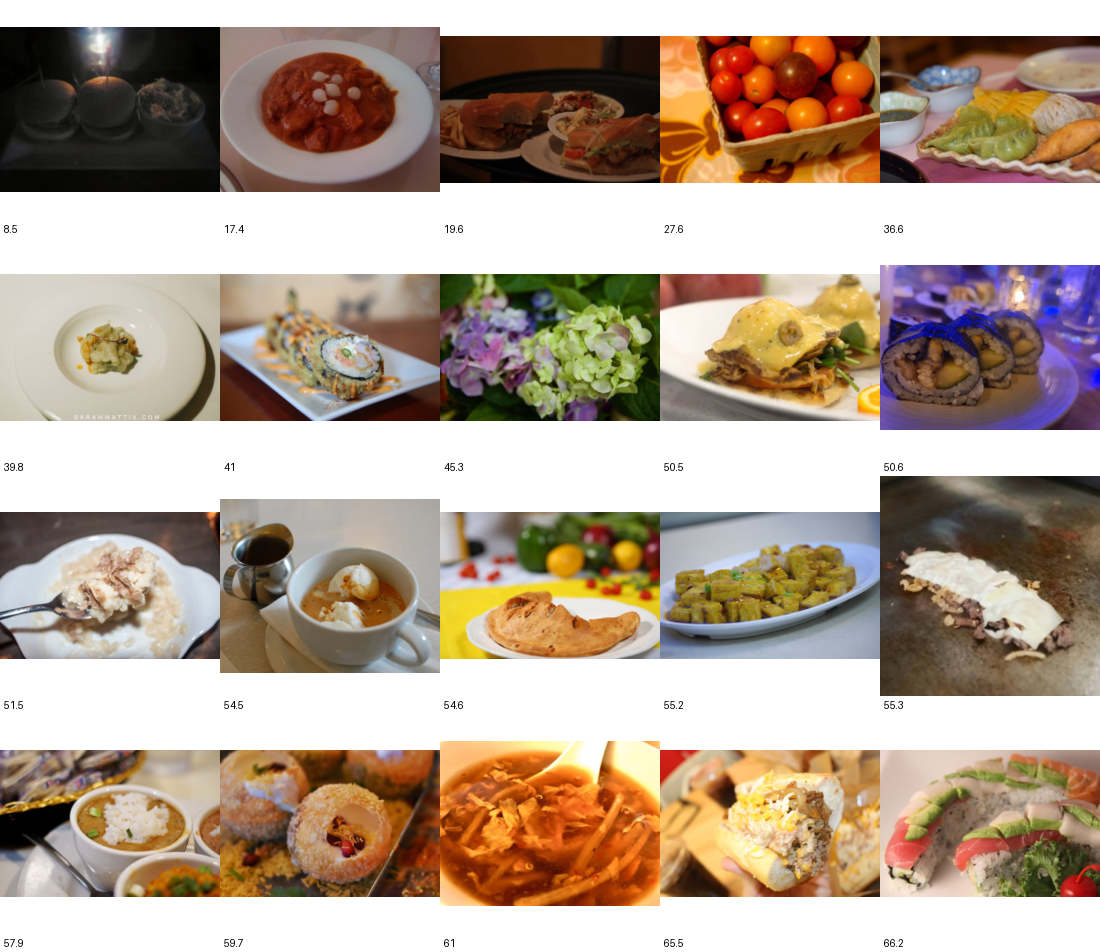

In [6]:
Show('diagnostics/_sheet_sharpness_measure.png')


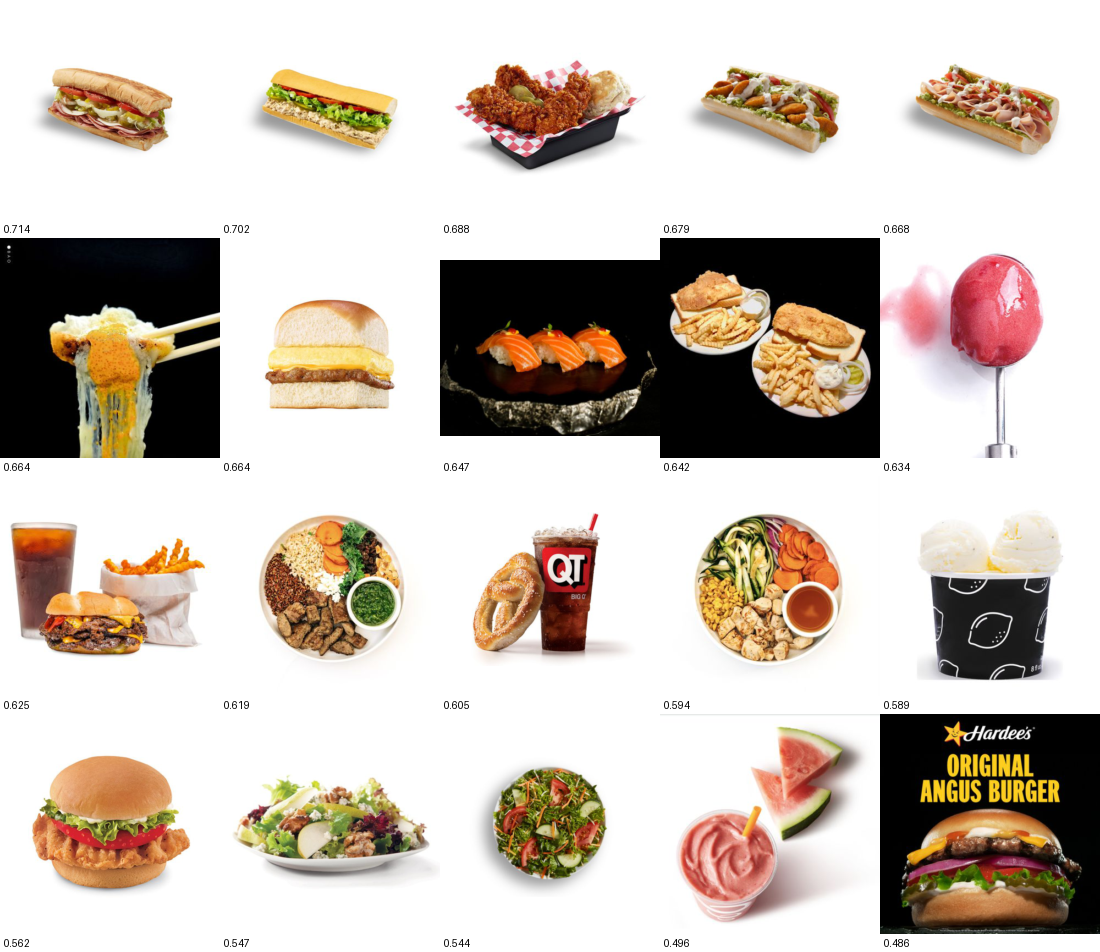

In [7]:
Show('diagnostics/_sheet_clipped.png')


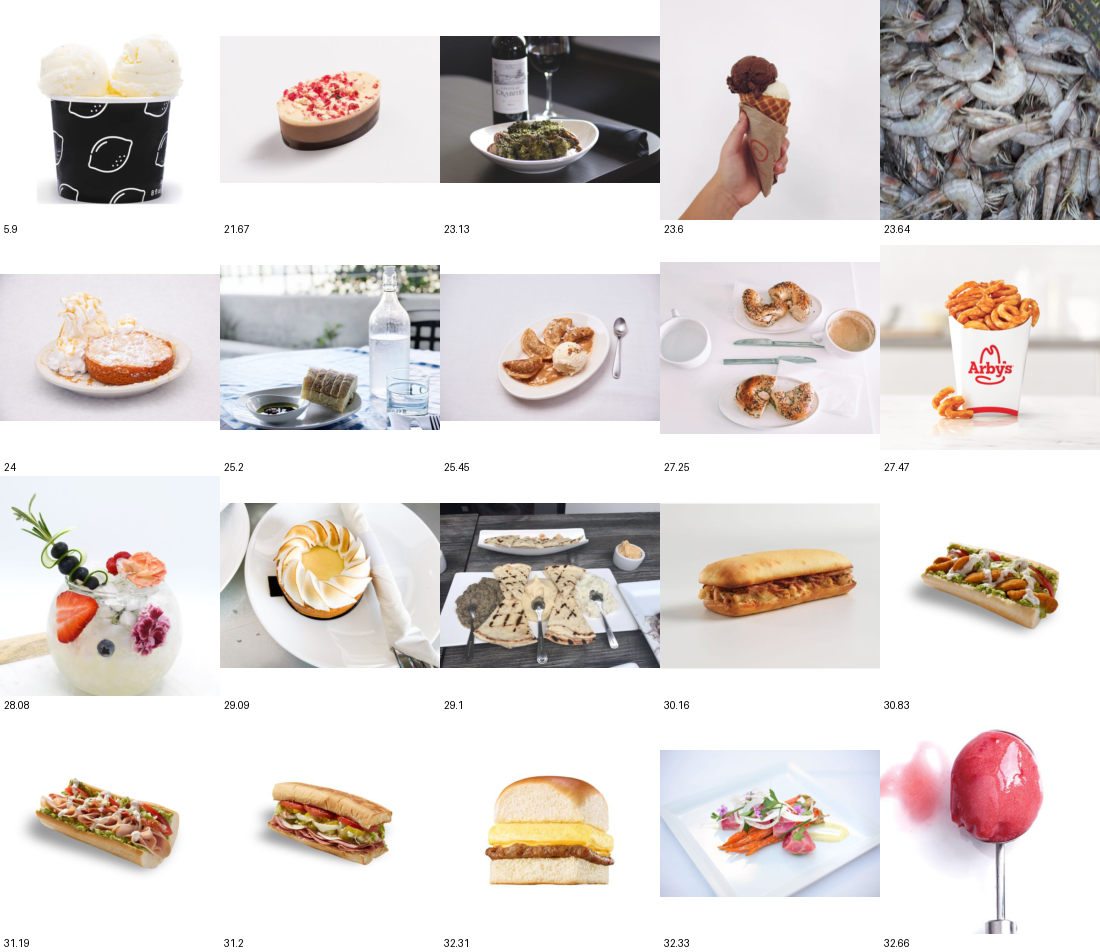

In [8]:
Show('diagnostics/_sheet_average_saturation.png')


### Ceiling
**Nothing is cut on these.** They answer whether is there room left for the edit to work?

A photograph already at the top of an axis cannot be pushed further along it, so an edit that raises that axis has nothing to do.

it is used to make a judgement after looking, and to state in the write-up if you act on it.


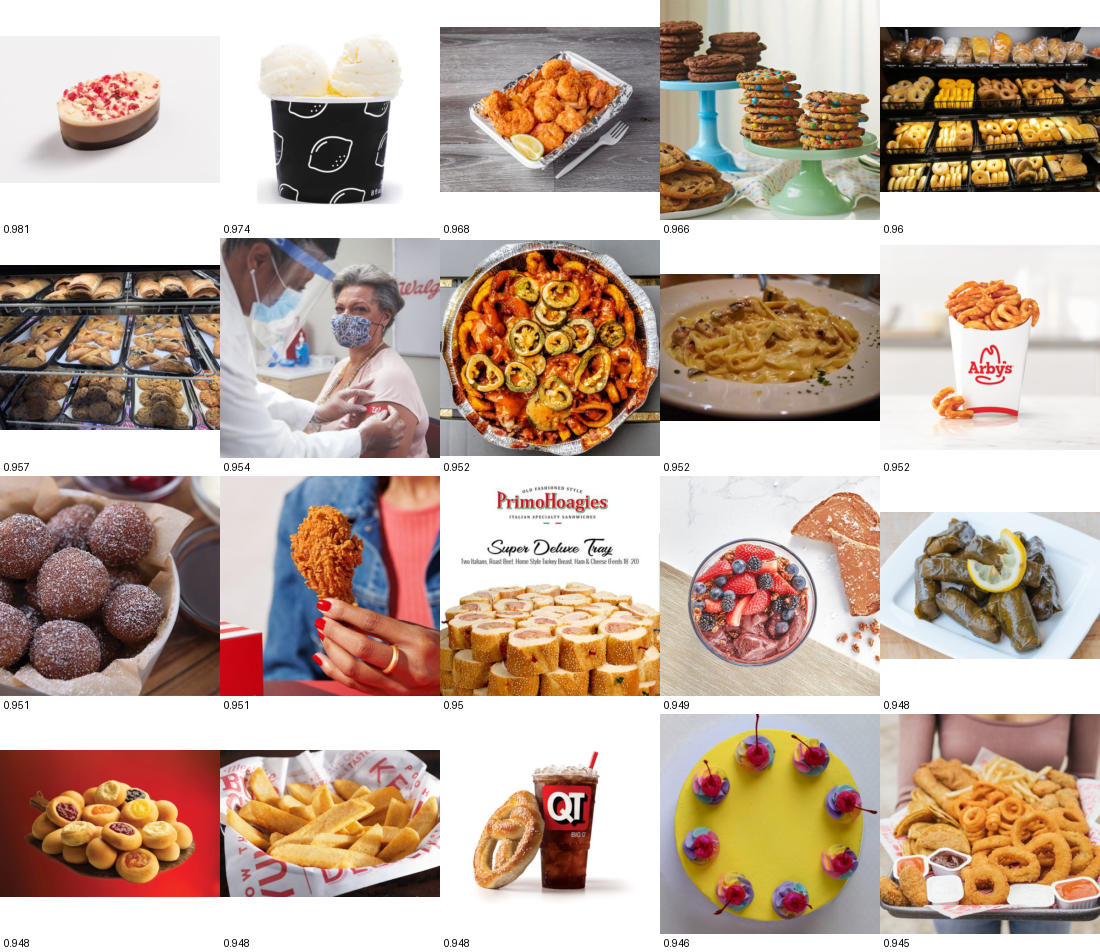

In [9]:
Show('diagnostics/_sheet_memory_score.png')


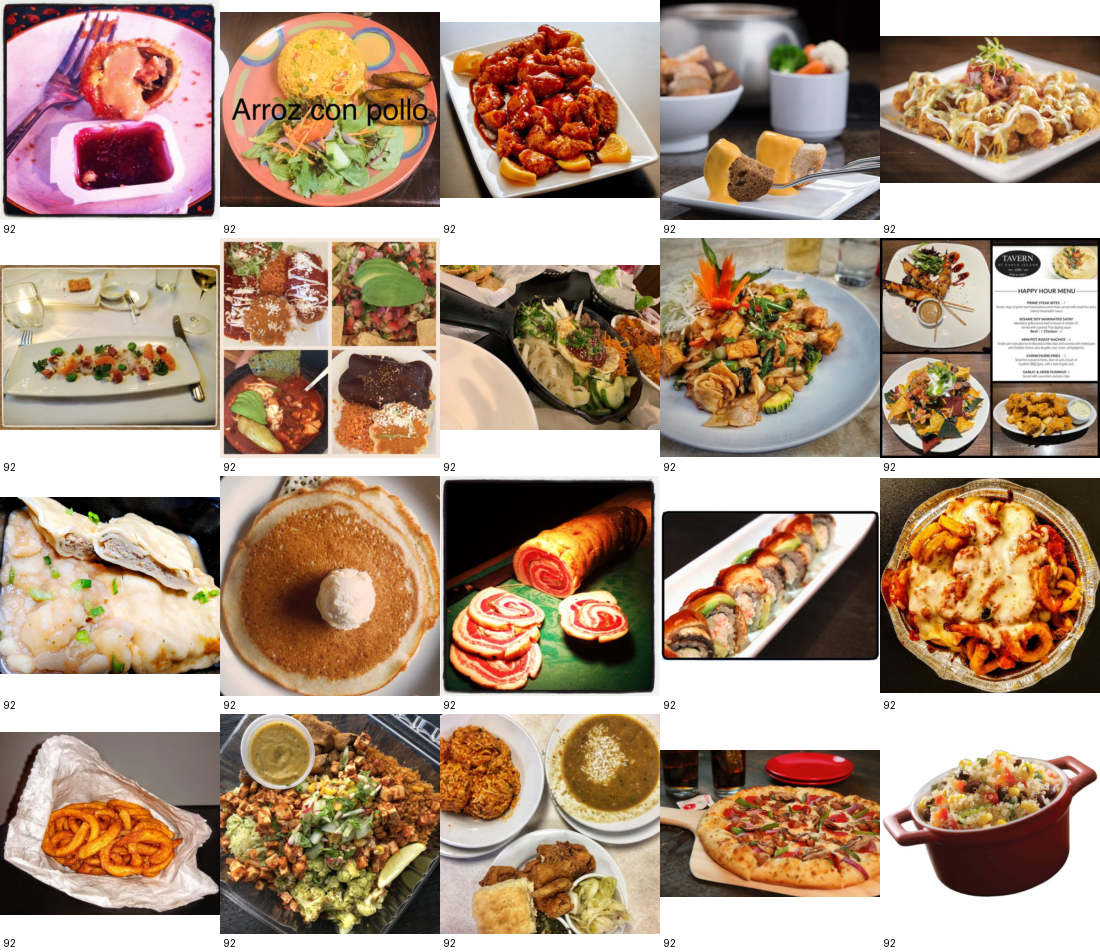

In [10]:
Show('diagnostics/_sheet_auto_bbox_pct.png')

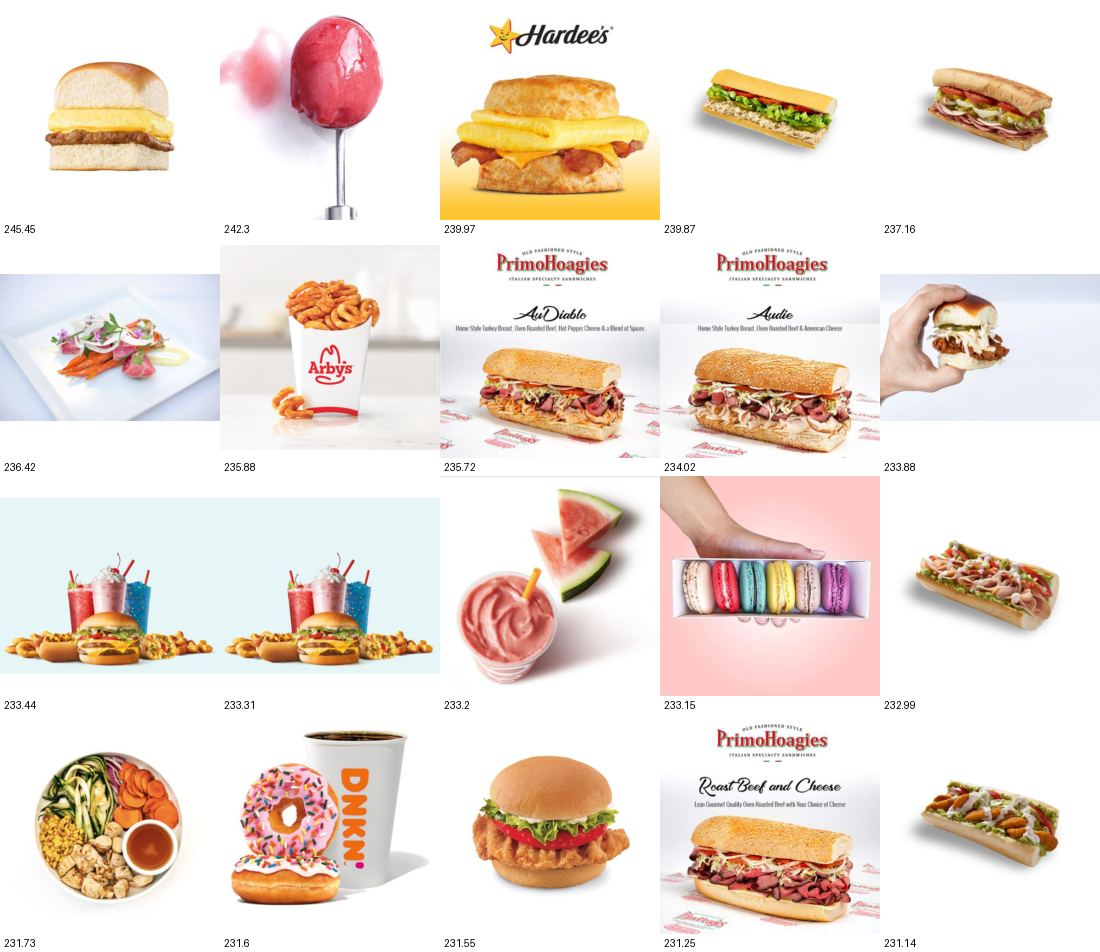

In [11]:
Show('diagnostics/_sheet_average_value.png')


## 6. Read the distributions

Two things to check before going further.

First, files that Stage A dropped on size or shape. Secondly, `pool.csv` holds one row per photograph that reached Stage B, carrying both
Stage A's measurements.


In [12]:
print(open('pool_summary.txt').read())

prefilter.py  2026-10-09 11:33
command: prefilter.py ../food_photos --out-dir pool --out-csv pool.csv --target 1000 --auto

files found                   108,152
  stage A, too small                47,801
  stage A, unreadable                  105
usable size                    60,246
  not sampled                    58,896
measured                        1,350
  stage B, duplicate                   110
  stage B, clipped                     107
  stage B, blurred                      62
  stage B, interior_seam                 8
  stage B, uniform_border|interior_seam        4
  stage B, uniform_border                1
passed                          1,058
  over --target 1,000              58
kept                            1,000

thresholds
  min_sharpness      111.8        bottom 5% of your photos
  max_clipped        0.1          fixed: >10% of pixels blown or crushed
  min_saturation     10.0         fixed: true greyscale only (0-255 scale)
  drop_flagged       1            --aut

In [13]:
df = pd.read_csv('pool.csv')
print('rows measured:', len(df))
print()
print(df['rejected'].fillna('(kept)').value_counts())
print()
kept = df[df['rejected'].isna()]
kept[['short_side', 'auto_bbox_pct', 'memory_score',
      'sharpness_measure', 'average_value', 'average_saturation']].describe().round(2)


rows measured: 1350

rejected
(kept)                          1000
duplicate                        110
clipped                          107
blurred                           62
over --target                     58
interior_seam                      8
uniform_border|interior_seam       4
uniform_border                     1
Name: count, dtype: int64



,short_side,auto_bbox_pct,memory_score,sharpness_measure,average_value,average_saturation
count,1000.0,972.00,1000.00,1000.00,1000.00,1000.00
mean,400.0,68.66,0.79,855.70,157.81,108.53
std,0.0,15.92,0.08,841.34,34.93,36.52
min,400.0,9.00,0.56,111.80,33.21,23.13
25%,400.0,59.00,0.73,343.48,132.91,82.80
50%,400.0,71.00,0.79,614.10,159.66,108.22
75%,400.0,81.00,0.84,1060.78,184.07,130.70
max,400.0,92.00,0.97,8556.10,236.42,227.80


## 7. Move a threshold, if you need to

`--reuse` re-reads the measurements already in `pool.csv` instead of opening
the photographs again. Any threshold you
pass overrides the one `--auto` chose for that measurement.

Set the value you read off the sheet in step 5, then run the cell. Leave it
at `None` to skip.


In [14]:
MIN_SHARPNESS  = 45    # e.g. 120
MAX_CLIPPED    = None      # e.g. 0.10
MIN_SATURATION = None      # e.g. 10
VALUE_RANGE    = None      # e.g. (40, 235)

opts = []
if MIN_SHARPNESS  is not None: opts += ['--min-sharpness',  str(MIN_SHARPNESS)]
if MAX_CLIPPED    is not None: opts += ['--max-clipped',    str(MAX_CLIPPED)]
if MIN_SATURATION is not None: opts += ['--min-saturation', str(MIN_SATURATION)]
if VALUE_RANGE    is not None: opts += ['--value-range', str(VALUE_RANGE[0]),
                                                         str(VALUE_RANGE[1])]
extra = ' '.join(opts)

if not extra:
    print('nothing set — skipping')
else:
    print('re-running with', extra)
    run_prefilter(['--reuse', *opts])


re-running with --min-sharpness 45


reusing 1,350 measurements from pool.csv


cuts applied


  min_sharpness        45.0       you set this


  max_clipped          0.1        fixed: >10% of pixels blown or crushed


  min_saturation       10.0       fixed: true greyscale only (0-255 scale)


... (40 outputs left out)

                                     20th is at 92


  _sheet_memory_score.png            highest first—can any edit still move these?


                                     20th is at 0.945


Next step is using AI to do further filter: dish category, people, text


In [17]:
import numpy as np
from PIL import Image as PILImage, ImageDraw

MAX_MEMORY = None        # e.g. 0.90, or None to keep every photograph
MAX_DIST   = 40    # near-duplicate search, out of 256 bits
DROP       = ['Cz02qqqaorQSmfYeXAXL_g.jpg', 'GQuNXs26cj7GSHkPilUceA.jpg', 'KsOuoOdplcduUEQQjFpWnQ.jpg']

pool = pd.read_csv('pool.csv')
pool = pool[pool['rejected'].isna()].copy()
print(f'kept by prefilter: {len(pool)}')

if MAX_MEMORY is not None and 'memory_score' in pool:
    before = len(pool)
    pool = pool[pool['memory_score'] < MAX_MEMORY]
    print(f'memory_score < {MAX_MEMORY}: {before} -> {len(pool)}')


# ---- 3. near-duplicates--------------------------
def dhash(path, n=16):
    """256 bits: is each pixel brighter than its right-hand neighbour,
    on a 17x16 grey thumbnail."""
    with PILImage.open(path) as im:
        g = np.asarray(im.convert('L').resize((n + 1, n), PILImage.BILINEAR),
                       dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

files = pool['filename'].tolist()
H = np.array([dhash(os.path.join('pool', f)) for f in files])
pairs = []
for i in range(len(files)):
    d = (H[i + 1:] != H[i]).sum(1)          # distance to every later photo
    for j in np.where(d <= MAX_DIST)[0]:
        pairs.append((int(d[j]), files[i], files[i + 1 + j]))
pairs.sort()
print(f'\nnear-duplicate candidates (distance <= {MAX_DIST}): {len(pairs)} pairs')

if pairs:
    cell, shown = 220, pairs[:60]
    sheet = PILImage.new('RGB', (2 * cell, len(shown) * (cell + 18)), 'white')
    draw = ImageDraw.Draw(sheet)
    for k, (dist, a, b) in enumerate(shown):
        y = k * (cell + 18)
        for x, f in ((0, a), (cell, b)):
            with PILImage.open(os.path.join('pool', f)) as im:
                im = im.convert('RGB'); im.thumbnail((cell - 6, cell - 6))
                sheet.paste(im, (x + 3, y + 3))
        draw.text((4, y + cell + 2), f'{dist}   drop? {b}', fill='black')
    sheet.save('diagnostics/_near_duplicates.png')
    if not DROP:
        print('look at diagnostics/_near_duplicates.png; for each pair that IS the same')
        print('photo, copy the right-hand filename into DROP and re-run this cell'
              + (f'  (first 60 of {len(pairs)} drawn)' if len(pairs) > 60 else ''))

if DROP:
    before = len(pool)
    pool = pool[~pool['filename'].isin(DROP)]
    print(f'dropped as near-duplicates: {before} -> {len(pool)}')


# framing: stratify
pool['bbox_group'] = pd.qcut(pool['auto_bbox_pct'].rank(method='first'), 4,
                             labels=['Q1', 'Q2', 'Q3', 'Q4'])
print()
print(pool.groupby('bbox_group', observed=True)['auto_bbox_pct']
          .agg(['count', 'min', 'max']))

nogroup = pool['bbox_group'].isna().sum()
if nogroup:
    print(f'{nogroup} with no framing measurement')

pool.to_csv('pool_final.csv', index=False)
print(f'\nwrote pool_final.csv ({len(pool)} rows)')

kept by prefilter: 1000



near-duplicate candidates (distance <= 40): 3 pairs
dropped as near-duplicates: 1000 -> 997

            count   min   max
bbox_group                   
Q1            243   9.0  59.0
Q2            243  59.0  71.0
Q3            242  71.0  81.0
Q4            243  81.0  92.0
26 with no framing measurement

wrote pool_final.csv (997 rows)


## 8. When the rehearsal looks right

Go back to step 3, set `LIMIT = None`, and run the notebook again from there.

After the full run, `pool/` holds the candidates and `pool.csv` holds every
measurement, including the rejected rows. 

In [16]:
# shutil.rmtree('_rehearsal', ignore_errors=True)
# print('rehearsal folder removed' if LIMIT else 'full run complete')
